In [16]:
import pandas as pd

In [17]:
df=pd.read_csv("/content/covid_19_clean_complete.csv")

In [18]:
df

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.939110,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.153300,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.033900,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.506300,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.202700,17.873900,2020-01-22,0,0,0,0,Africa
...,...,...,...,...,...,...,...,...,...,...
49063,NaN,Sao Tome and Principe,0.186400,6.613100,2020-07-27,865,14,734,117,Africa
49064,NaN,Yemen,15.552727,48.516388,2020-07-27,1691,483,833,375,Eastern Mediterranean
49065,NaN,Comoros,-11.645500,43.333300,2020-07-27,354,7,328,19,Africa
49066,NaN,Tajikistan,38.861000,71.276100,2020-07-27,7235,60,6028,1147,Europe


In [19]:
df.shape

(49068, 10)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB


In [21]:
df.rename(columns={
    "Country/Region":"Country",
    "Province/State":"State"
},inplace=True)

In [22]:
df

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.939110,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.153300,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.033900,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.506300,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.202700,17.873900,2020-01-22,0,0,0,0,Africa
...,...,...,...,...,...,...,...,...,...,...
49063,NaN,Sao Tome and Principe,0.186400,6.613100,2020-07-27,865,14,734,117,Africa
49064,NaN,Yemen,15.552727,48.516388,2020-07-27,1691,483,833,375,Eastern Mediterranean
49065,NaN,Comoros,-11.645500,43.333300,2020-07-27,354,7,328,19,Africa
49066,NaN,Tajikistan,38.861000,71.276100,2020-07-27,7235,60,6028,1147,Europe


In [23]:
df['Date'].value_counts()

,count
Date,
2020-01-22,261
2020-01-23,261
2020-01-24,261
2020-01-25,261
2020-01-26,261
...,...
2020-07-23,261
2020-07-24,261
2020-07-25,261


In [24]:
# Group by
# Confiremed Cases
# Date -> Confirmed -> sum() -> reset_index()

confirmed_cases=df.groupby(["Date"])["Confirmed"].sum().reset_index()
confirmed_cases

,Date,Confirmed
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

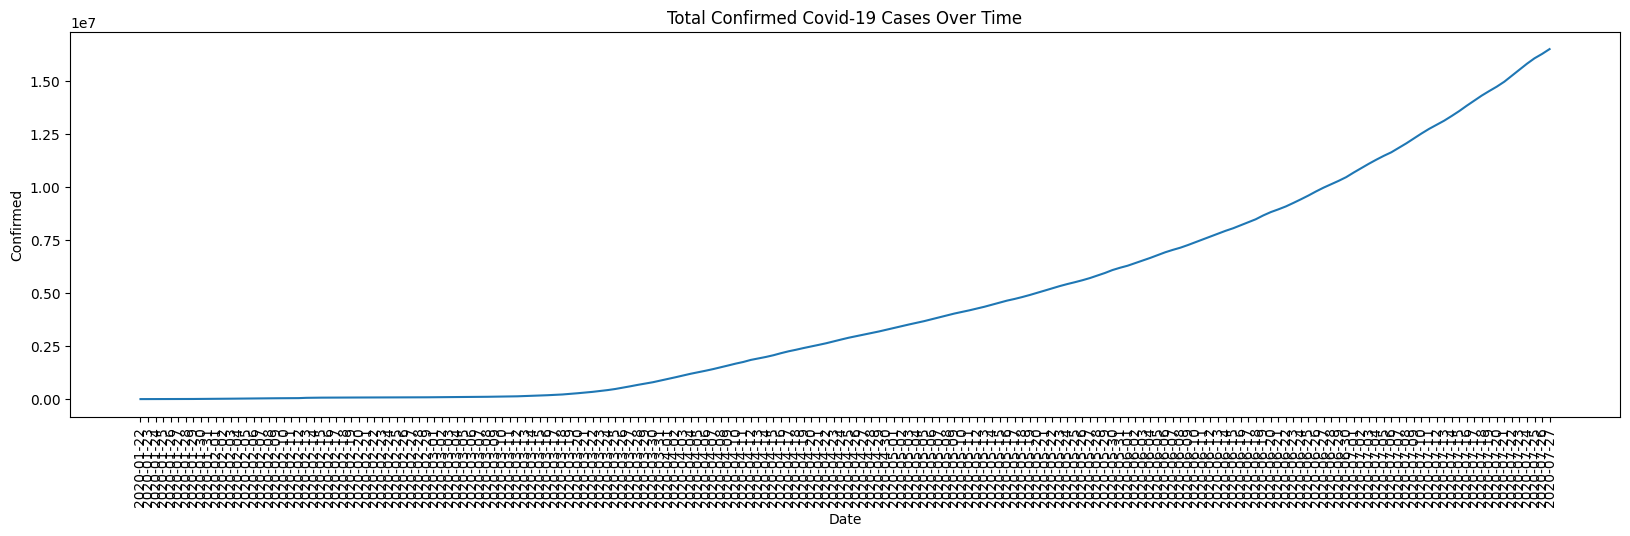

In [84]:
plt.figure(figsize=(20,5))
sns.lineplot(data=confirmed_cases,x="Date",y="Confirmed")
plt.xticks(rotation=90)
plt.title("Total Confirmed Covid-19 Cases Over Time")
plt.show()

In [27]:
#Death cases -> groupby -> plot

In [28]:
df.columns

Index(['State', 'Country', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths',
       'Recovered', 'Active', 'WHO Region'],
      dtype='object')

In [29]:
death_cases=df.groupby(["Date"])["Deaths"].sum().reset_index()
death_cases

,Date,Deaths
0,2020-01-22,17
1,2020-01-23,18
2,2020-01-24,26
3,2020-01-25,42
4,2020-01-26,56
...,...,...
183,2020-07-23,633506
184,2020-07-24,639650
185,2020-07-25,644517
186,2020-07-26,648621


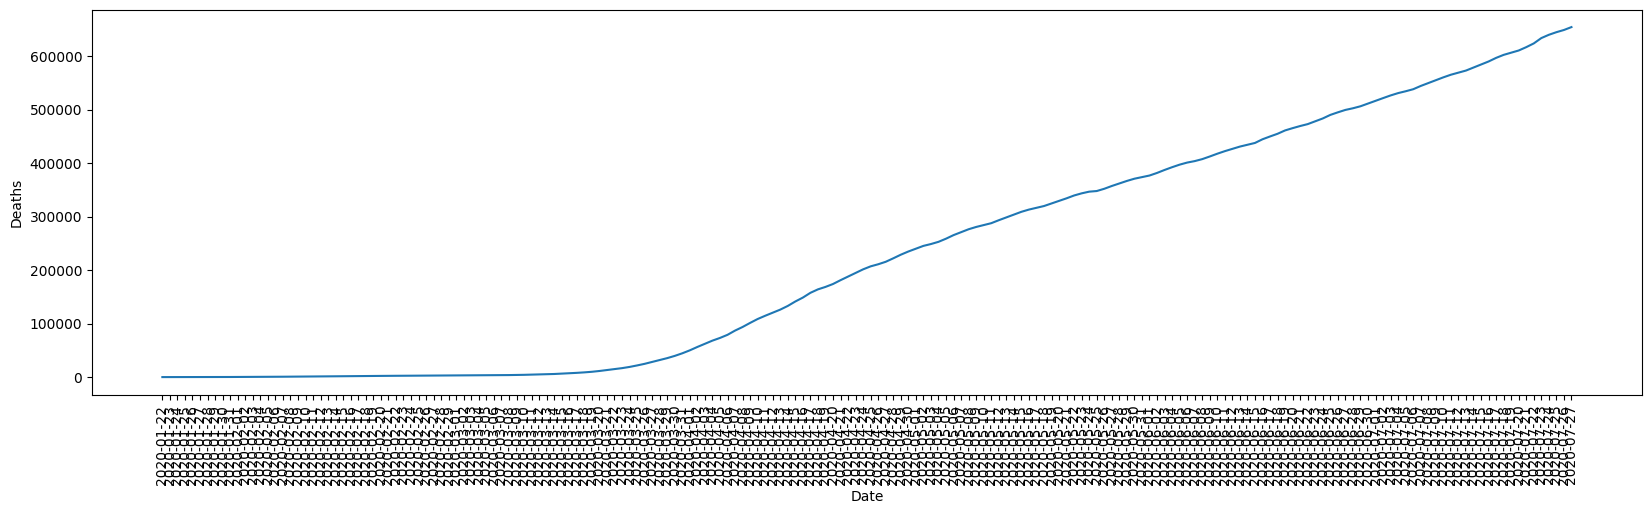

In [30]:
plt.figure(figsize=(20,5))
sns.lineplot(data=death_cases, x="Date", y="Deaths")
plt.xticks(rotation=90)
plt.show()

In [31]:
# Find out the most affected countries
# 3 top most affected countries
# Confirmed, Active, Recover, Death Cases

In [32]:
df.columns

Index(['State', 'Country', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths',
       'Recovered', 'Active', 'WHO Region'],
      dtype='object')

In [33]:
data_countries = df.groupby("Country")[['Confirmed', 'Deaths','Recovered', 'Active']].sum().reset_index()

In [34]:
data_countries

,Country,Confirmed,Deaths,Recovered,Active
0,Afghanistan,1936390,49098,798240,1089052
1,Albania,196702,5708,118877,72117
2,Algeria,1179755,77972,755897,345886
3,Andorra,94404,5423,69074,19907
4,Angola,22662,1078,6573,15011
...,...,...,...,...,...
182,West Bank and Gaza,233461,1370,61124,170967
183,Western Sahara,901,63,648,190
184,Yemen,67180,17707,23779,25694
185,Zambia,129421,2643,83611,43167


In [35]:
top3_confirmed = data_countries.sort_values(by="Confirmed", ascending=False).head(3)

In [36]:
top3_confirmed

,Country,Confirmed,Deaths,Recovered,Active
173,US,224345948,11011411,56353416,156981121
23,Brazil,89524967,3938034,54492873,31094060
138,Russia,45408411,619385,25120448,19668578


In [37]:
top3_death = data_countries.sort_values(by="Deaths", ascending=False).head(3)

In [38]:
top3_death

,Country,Confirmed,Deaths,Recovered,Active
173,US,224345948,11011411,56353416,156981121
177,United Kingdom,26748587,3997775,126217,22624595
23,Brazil,89524967,3938034,54492873,31094060


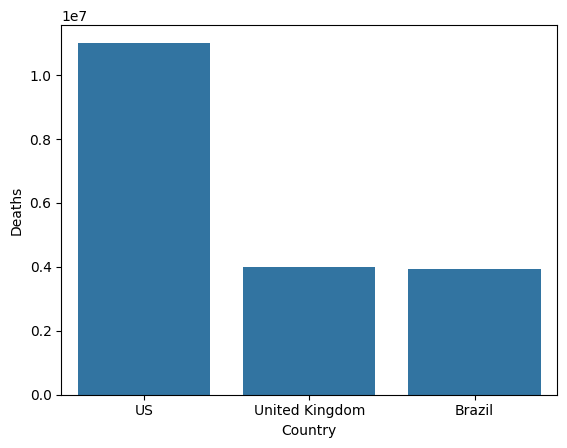

In [39]:
sns.barplot(data=top3_death, x="Country", y="Deaths")
plt.show()

In [40]:
us = df[df["Country"]=="US"]
us

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
223,NaN,US,40.0,-100.0,2020-01-22,1,0,0,1,Americas
484,NaN,US,40.0,-100.0,2020-01-23,1,0,0,1,Americas
745,NaN,US,40.0,-100.0,2020-01-24,2,0,0,2,Americas
1006,NaN,US,40.0,-100.0,2020-01-25,2,0,0,2,Americas
1267,NaN,US,40.0,-100.0,2020-01-26,5,0,0,5,Americas
...,...,...,...,...,...,...,...,...,...,...
47986,NaN,US,40.0,-100.0,2020-07-23,4038816,144430,1233269,2661117,Americas
48247,NaN,US,40.0,-100.0,2020-07-24,4112531,145560,1261624,2705347,Americas
48508,NaN,US,40.0,-100.0,2020-07-25,4178970,146465,1279414,2753091,Americas
48769,NaN,US,40.0,-100.0,2020-07-26,4233923,146935,1297863,2789125,Americas


In [41]:
df.columns

Index(['State', 'Country', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths',
       'Recovered', 'Active', 'WHO Region'],
      dtype='object')

In [42]:
data_us = us.groupby("Date")[['Confirmed', 'Deaths', 'Recovered', 'Active']].sum().reset_index()

In [43]:
data_us

,Date,Confirmed,Deaths,Recovered,Active
0,2020-01-22,1,0,0,1
1,2020-01-23,1,0,0,1
2,2020-01-24,2,0,0,2
3,2020-01-25,2,0,0,2
4,2020-01-26,5,0,0,5
...,...,...,...,...,...
183,2020-07-23,4038816,144430,1233269,2661117
184,2020-07-24,4112531,145560,1261624,2705347
185,2020-07-25,4178970,146465,1279414,2753091
186,2020-07-26,4233923,146935,1297863,2789125


In [44]:
#Brazil
#Russia

In [45]:
brazil=df[df["Country"]=="Brazil"]
brazil

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
28,NaN,Brazil,-14.235,-51.9253,2020-01-22,0,0,0,0,Americas
289,NaN,Brazil,-14.235,-51.9253,2020-01-23,0,0,0,0,Americas
550,NaN,Brazil,-14.235,-51.9253,2020-01-24,0,0,0,0,Americas
811,NaN,Brazil,-14.235,-51.9253,2020-01-25,0,0,0,0,Americas
1072,NaN,Brazil,-14.235,-51.9253,2020-01-26,0,0,0,0,Americas
...,...,...,...,...,...,...,...,...,...,...
47791,NaN,Brazil,-14.235,-51.9253,2020-07-23,2287475,84082,1620313,583080,Americas
48052,NaN,Brazil,-14.235,-51.9253,2020-07-24,2343366,85238,1693214,564914,Americas
48313,NaN,Brazil,-14.235,-51.9253,2020-07-25,2394513,86449,1785359,522705,Americas
48574,NaN,Brazil,-14.235,-51.9253,2020-07-26,2419091,87004,1812913,519174,Americas


In [46]:
data_brazil = brazil.groupby("Date")[['Confirmed', 'Deaths', 'Recovered', 'Active']].sum().reset_index()

In [47]:
data_brazil

,Date,Confirmed,Deaths,Recovered,Active
0,2020-01-22,0,0,0,0
1,2020-01-23,0,0,0,0
2,2020-01-24,0,0,0,0
3,2020-01-25,0,0,0,0
4,2020-01-26,0,0,0,0
...,...,...,...,...,...
183,2020-07-23,2287475,84082,1620313,583080
184,2020-07-24,2343366,85238,1693214,564914
185,2020-07-25,2394513,86449,1785359,522705
186,2020-07-26,2419091,87004,1812913,519174


In [48]:
russia=df[df["Country"]=="Russia"]
russia

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
185,NaN,Russia,61.52401,105.318756,2020-01-22,0,0,0,0,Europe
446,NaN,Russia,61.52401,105.318756,2020-01-23,0,0,0,0,Europe
707,NaN,Russia,61.52401,105.318756,2020-01-24,0,0,0,0,Europe
968,NaN,Russia,61.52401,105.318756,2020-01-25,0,0,0,0,Europe
1229,NaN,Russia,61.52401,105.318756,2020-01-26,0,0,0,0,Europe
...,...,...,...,...,...,...,...,...,...,...
47948,NaN,Russia,61.52401,105.318756,2020-07-23,793720,12873,579295,201552,Europe
48209,NaN,Russia,61.52401,105.318756,2020-07-24,799499,13026,587728,198745,Europe
48470,NaN,Russia,61.52401,105.318756,2020-07-25,805332,13172,596064,196096,Europe
48731,NaN,Russia,61.52401,105.318756,2020-07-26,811073,13249,599172,198652,Europe


In [49]:
data_russia = russia.groupby("Date")[['Confirmed', 'Deaths', 'Recovered', 'Active']].sum().reset_index()

In [50]:
data_russia

,Date,Confirmed,Deaths,Recovered,Active
0,2020-01-22,0,0,0,0
1,2020-01-23,0,0,0,0
2,2020-01-24,0,0,0,0
3,2020-01-25,0,0,0,0
4,2020-01-26,0,0,0,0
...,...,...,...,...,...
183,2020-07-23,793720,12873,579295,201552
184,2020-07-24,799499,13026,587728,198745
185,2020-07-25,805332,13172,596064,196096
186,2020-07-26,811073,13249,599172,198652


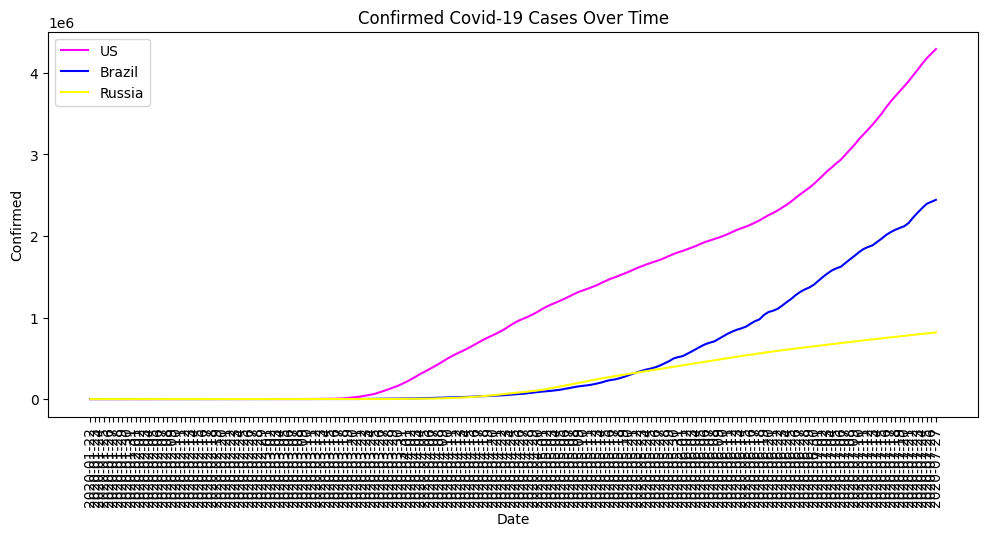

In [60]:
#Confirmed
plt.figure(figsize=(12,5))
sns.lineplot(data=data_us, x="Date", y="Confirmed", color="Magenta", label="US")
sns.lineplot(data=data_brazil, x="Date", y="Confirmed", color="blue", label="Brazil")
sns.lineplot(data=data_russia, x="Date", y="Confirmed", color="yellow", label="Russia")
plt.xticks(rotation=90)
plt.title("Confirmed Covid-19 Cases Over Time")
plt.legend()
plt.show()

In [52]:
df.columns

Index(['State', 'Country', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths',
       'Recovered', 'Active', 'WHO Region'],
      dtype='object')

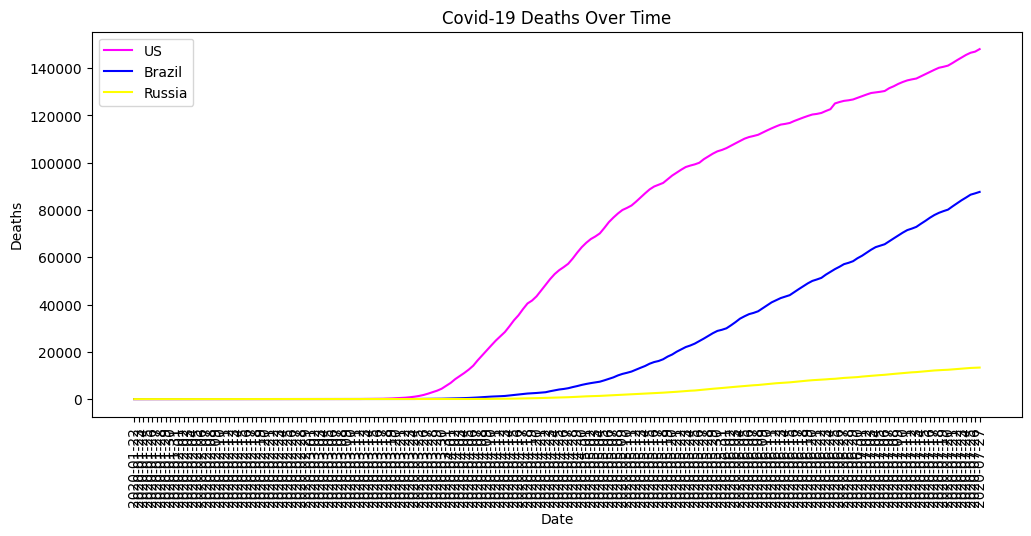

In [61]:
#Deaths
plt.figure(figsize=(12,5))
sns.lineplot(data=data_us, x="Date", y="Deaths", color="Magenta", label="US")
sns.lineplot(data=data_brazil, x="Date", y="Deaths", color="blue", label="Brazil")
sns.lineplot(data=data_russia, x="Date", y="Deaths", color="yellow", label="Russia")
plt.xticks(rotation=90)
plt.title("Covid-19 Deaths Over Time")
plt.legend()
plt.show()

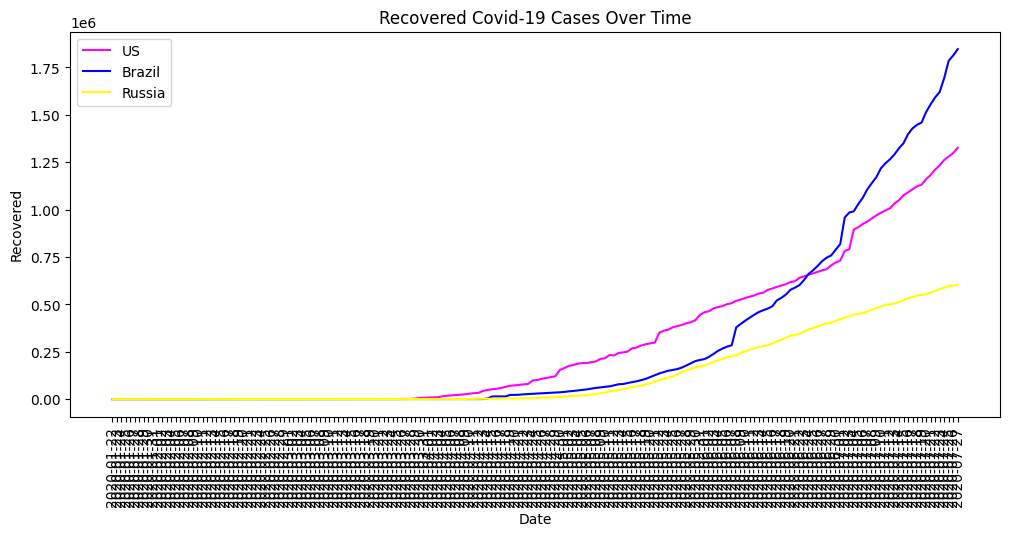

In [59]:
#Recovered
plt.figure(figsize=(12,5))
sns.lineplot(data=data_us, x="Date", y="Recovered", color="Magenta", label="US")
sns.lineplot(data=data_brazil, x="Date", y="Recovered", color="blue", label="Brazil")
sns.lineplot(data=data_russia, x="Date", y="Recovered", color="yellow", label="Russia")
plt.xticks(rotation=90)
plt.title("Recovered Covid-19 Cases Over Time")
plt.legend()
plt.show()

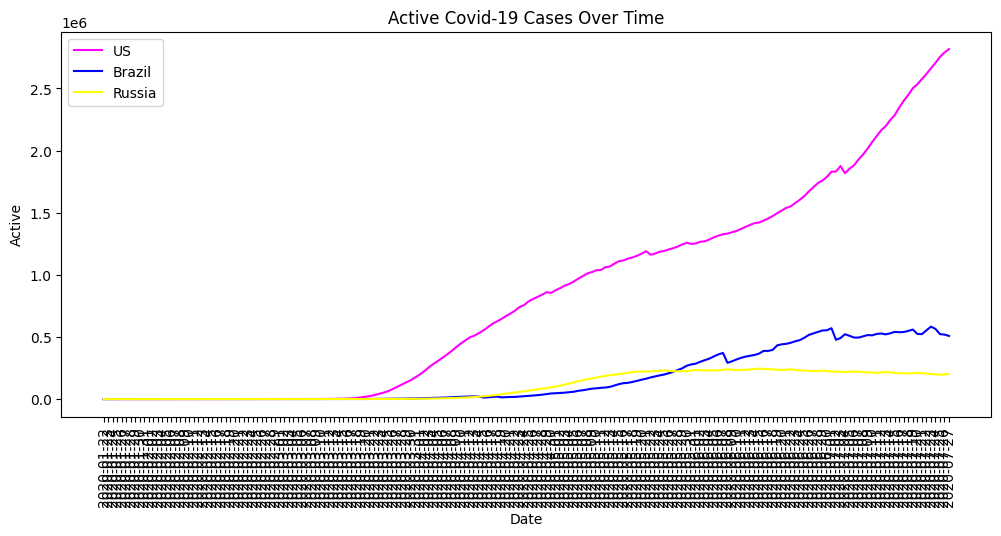

In [58]:
#Active
plt.figure(figsize=(12,5))
sns.lineplot(data=data_us, x="Date", y="Active", color="Magenta", label="US")
sns.lineplot(data=data_brazil, x="Date", y="Active", color="blue", label="Brazil")
sns.lineplot(data=data_russia, x="Date", y="Active", color="yellow", label="Russia")
plt.xticks(rotation=90)
plt.title("Active Covid-19 Cases Over Time")
plt.legend()
plt.show()

In [62]:
# Prophet -> It is a timeseries forecasting tool / model developed by Facebook and that's designed to be easy to use and effective for a wide range of time series data

In [63]:
# It is perticullarly useful for the data that has string seasonal effects (daily, monthly , weekly)

In [64]:
!pip install prophet

In [65]:
from prophet import Prophet

In [66]:
#confirmed
confirmed_cases = df.groupby(["Date"])["Confirmed"].sum().reset_index()

In [67]:
confirmed_cases

,Date,Confirmed
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


In [68]:
# Date -> ds, value -> y

In [69]:
prophet_data = confirmed_cases.rename(columns={
    "Date" : "ds", "Confirmed" : "y"
})
prophet_data

,ds,y
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118
...,...,...
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796


In [70]:
model=Prophet()

In [71]:
model.fit(prophet_data)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [72]:
future = model.make_future_dataframe(periods=7)   # Forcasting for 7 days

In [73]:
future

,ds
0,2020-01-22
1,2020-01-23
2,2020-01-24
3,2020-01-25
4,2020-01-26
...,...
190,2020-07-30
191,2020-07-31
192,2020-08-01
193,2020-08-02


In [74]:
forecast = model.predict(future)
forecast

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2020-01-22,-1.035916e+04,-1.272903e+05,8.174651e+04,-1.035916e+04,-1.035916e+04,-11045.230807,-11045.230807,-11045.230807,-11045.230807,-11045.230807,-11045.230807,0.0,0.0,0.0,-2.140439e+04
1,2020-01-23,-7.617091e+03,-1.217829e+05,9.539358e+04,-7.617091e+03,-7.617091e+03,-1109.169058,-1109.169058,-1109.169058,-1109.169058,-1109.169058,-1109.169058,0.0,0.0,0.0,-8.726260e+03
2,2020-01-24,-4.875024e+03,-9.900782e+04,1.140879e+05,-4.875024e+03,-4.875024e+03,10132.112117,10132.112117,10132.112117,10132.112117,10132.112117,10132.112117,0.0,0.0,0.0,5.257088e+03
3,2020-01-25,-2.132956e+03,-9.587798e+04,1.212180e+05,-2.132956e+03,-2.132956e+03,13751.834873,13751.834873,13751.834873,13751.834873,13751.834873,13751.834873,0.0,0.0,0.0,1.161888e+04
4,2020-01-26,6.091115e+02,-9.735825e+04,1.091455e+05,6.091115e+02,6.091115e+02,7254.714658,7254.714658,7254.714658,7254.714658,7254.714658,7254.714658,0.0,0.0,0.0,7.863826e+03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,2020-07-30,1.674494e+07,1.663572e+07,1.684541e+07,1.674117e+07,1.674954e+07,-1109.169058,-1109.169058,-1109.169058,-1109.169058,-1109.169058,-1109.169058,0.0,0.0,0.0,1.674383e+07
191,2020-07-31,1.694894e+07,1.684926e+07,1.707200e+07,1.694136e+07,1.695901e+07,10132.112117,10132.112117,10132.112117,10132.112117,10132.112117,10132.112117,0.0,0.0,0.0,1.695907e+07
192,2020-08-01,1.715294e+07,1.705247e+07,1.727321e+07,1.713653e+07,1.717137e+07,13751.834873,13751.834873,13751.834873,13751.834873,13751.834873,13751.834873,0.0,0.0,0.0,1.716669e+07
193,2020-08-02,1.735694e+07,1.724725e+07,1.747772e+07,1.733169e+07,1.738519e+07,7254.714658,7254.714658,7254.714658,7254.714658,7254.714658,7254.714658,0.0,0.0,0.0,1.736419e+07


In [75]:
forecast[["ds", "yhat_lower", "yhat_upper", "yhat"]]

,ds,yhat_lower,yhat_upper,yhat
0,2020-01-22,-1.272903e+05,8.174651e+04,-2.140439e+04
1,2020-01-23,-1.217829e+05,9.539358e+04,-8.726260e+03
2,2020-01-24,-9.900782e+04,1.140879e+05,5.257088e+03
3,2020-01-25,-9.587798e+04,1.212180e+05,1.161888e+04
4,2020-01-26,-9.735825e+04,1.091455e+05,7.863826e+03
...,...,...,...,...
190,2020-07-30,1.663572e+07,1.684541e+07,1.674383e+07
191,2020-07-31,1.684926e+07,1.707200e+07,1.695907e+07
192,2020-08-01,1.705247e+07,1.727321e+07,1.716669e+07
193,2020-08-02,1.724725e+07,1.747772e+07,1.736419e+07


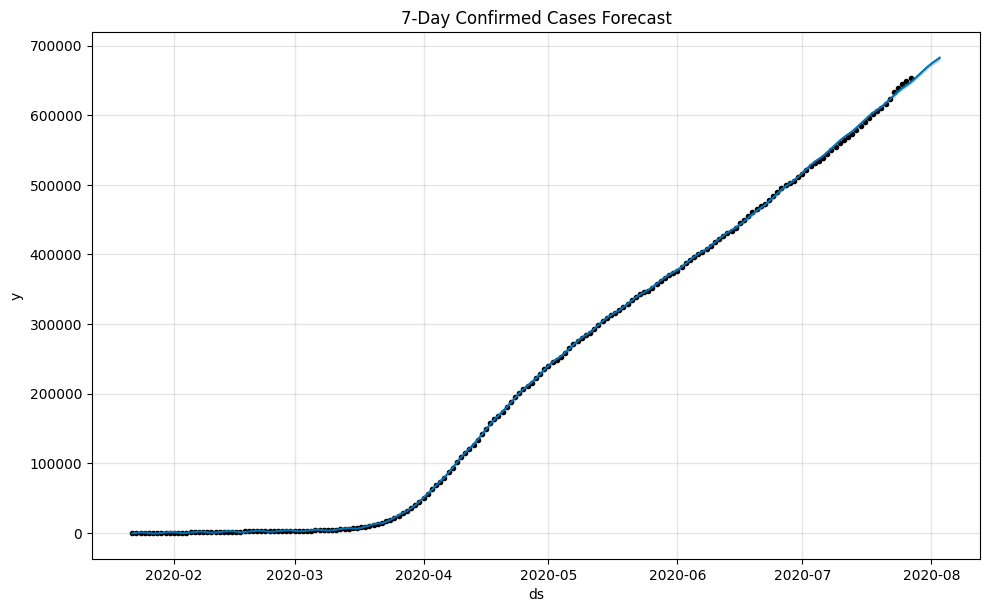

In [88]:
model.plot(forecast)
plt.title("7-Day Confirmed Cases Forecast")
plt.show()

In [79]:
death_cases = df.groupby(["Date"])["Deaths"].sum().reset_index()
death_cases

,Date,Deaths
0,2020-01-22,17
1,2020-01-23,18
2,2020-01-24,26
3,2020-01-25,42
4,2020-01-26,56
...,...,...
183,2020-07-23,633506
184,2020-07-24,639650
185,2020-07-25,644517
186,2020-07-26,648621


In [80]:
prophet_data = death_cases.rename(columns={
    "Date" : "ds", "Deaths" : "y"
})
prophet_data

,ds,y
0,2020-01-22,17
1,2020-01-23,18
2,2020-01-24,26
3,2020-01-25,42
4,2020-01-26,56
...,...,...
183,2020-07-23,633506
184,2020-07-24,639650
185,2020-07-25,644517
186,2020-07-26,648621


In [81]:
model=Prophet()
model.fit(prophet_data)
future = model.make_future_dataframe(periods=7)
forecast = model.predict(future)
forecast

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2020-01-22,-451.705764,-2581.173562,1315.701377,-451.705764,-451.705764,-192.416266,-192.416266,-192.416266,-192.416266,-192.416266,-192.416266,0.0,0.0,0.0,-644.122031
1,2020-01-23,-368.379259,-1863.967326,2042.410683,-368.379259,-368.379259,387.965108,387.965108,387.965108,387.965108,387.965108,387.965108,0.0,0.0,0.0,19.585848
2,2020-01-24,-285.052754,-1404.765262,2587.886180,-285.052754,-285.052754,874.380896,874.380896,874.380896,874.380896,874.380896,874.380896,0.0,0.0,0.0,589.328142
3,2020-01-25,-201.726249,-1444.240872,2398.457011,-201.726249,-201.726249,726.838212,726.838212,726.838212,726.838212,726.838212,726.838212,0.0,0.0,0.0,525.111964
4,2020-01-26,-118.399743,-2291.893713,1536.747207,-118.399743,-118.399743,-164.824922,-164.824922,-164.824922,-164.824922,-164.824922,-164.824922,0.0,0.0,0.0,-283.224665
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190,2020-07-30,663118.678157,661414.681254,665637.720239,662793.744316,663343.910075,387.965108,387.965108,387.965108,387.965108,387.965108,387.965108,0.0,0.0,0.0,663506.643264
191,2020-07-31,668149.208164,666756.484227,671261.072803,667512.859953,668667.749856,874.380896,874.380896,874.380896,874.380896,874.380896,874.380896,0.0,0.0,0.0,669023.589060
192,2020-08-01,673179.738172,671414.471140,676268.272893,672203.961181,674072.197854,726.838212,726.838212,726.838212,726.838212,726.838212,726.838212,0.0,0.0,0.0,673906.576384
193,2020-08-02,678210.268179,675540.656696,680537.666343,676740.178086,679561.511490,-164.824922,-164.824922,-164.824922,-164.824922,-164.824922,-164.824922,0.0,0.0,0.0,678045.443257


In [82]:
forecast[["ds", "yhat_lower", "yhat_upper", "yhat"]]

,ds,yhat_lower,yhat_upper,yhat
0,2020-01-22,-2581.173562,1315.701377,-644.122031
1,2020-01-23,-1863.967326,2042.410683,19.585848
2,2020-01-24,-1404.765262,2587.886180,589.328142
3,2020-01-25,-1444.240872,2398.457011,525.111964
4,2020-01-26,-2291.893713,1536.747207,-283.224665
...,...,...,...,...
190,2020-07-30,661414.681254,665637.720239,663506.643264
191,2020-07-31,666756.484227,671261.072803,669023.589060
192,2020-08-01,671414.471140,676268.272893,673906.576384
193,2020-08-02,675540.656696,680537.666343,678045.443257


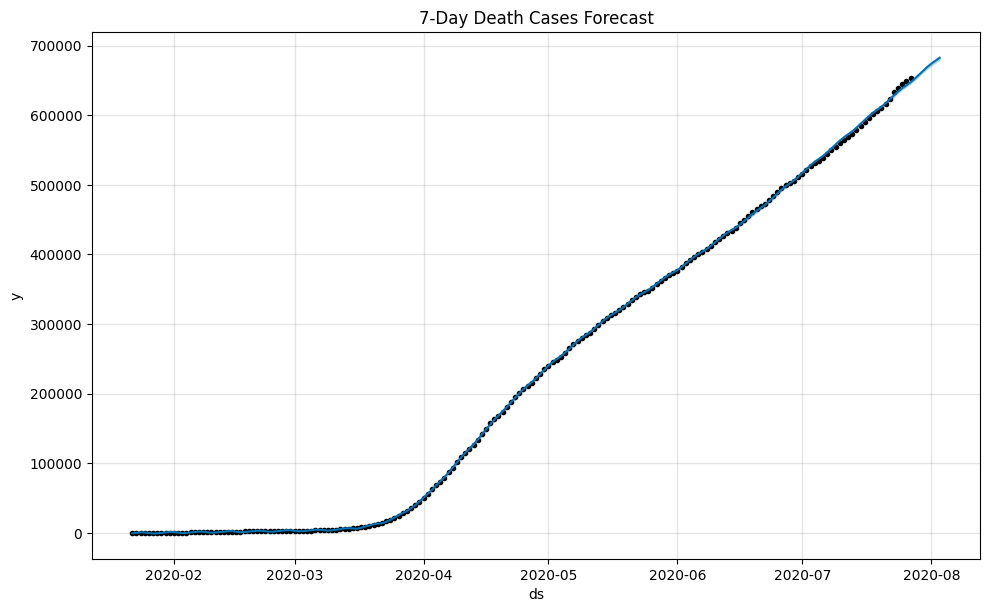

In [87]:
model.plot(forecast)
plt.title("7-Day Death Cases Forecast")
plt.show()

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


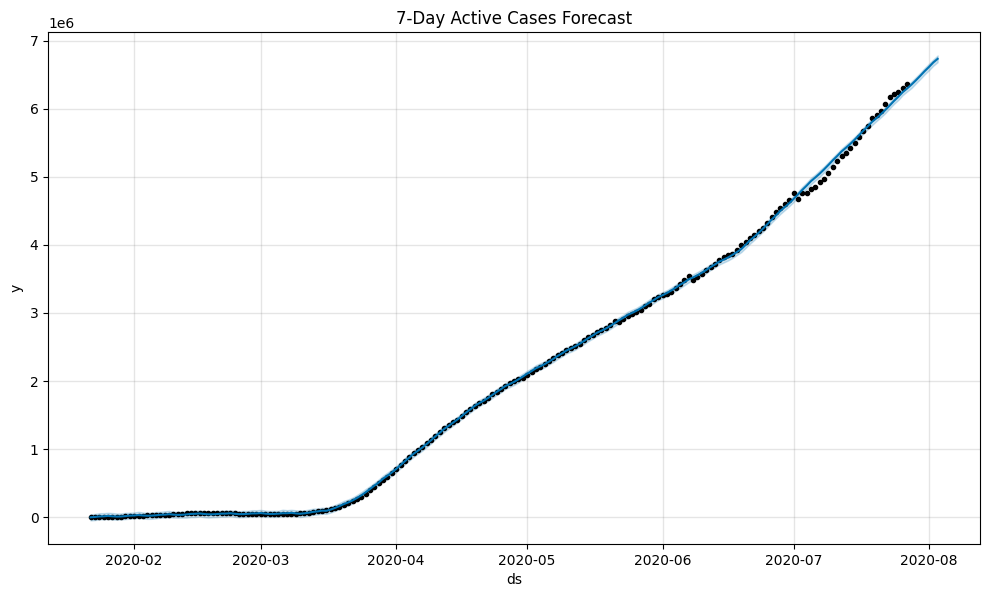

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


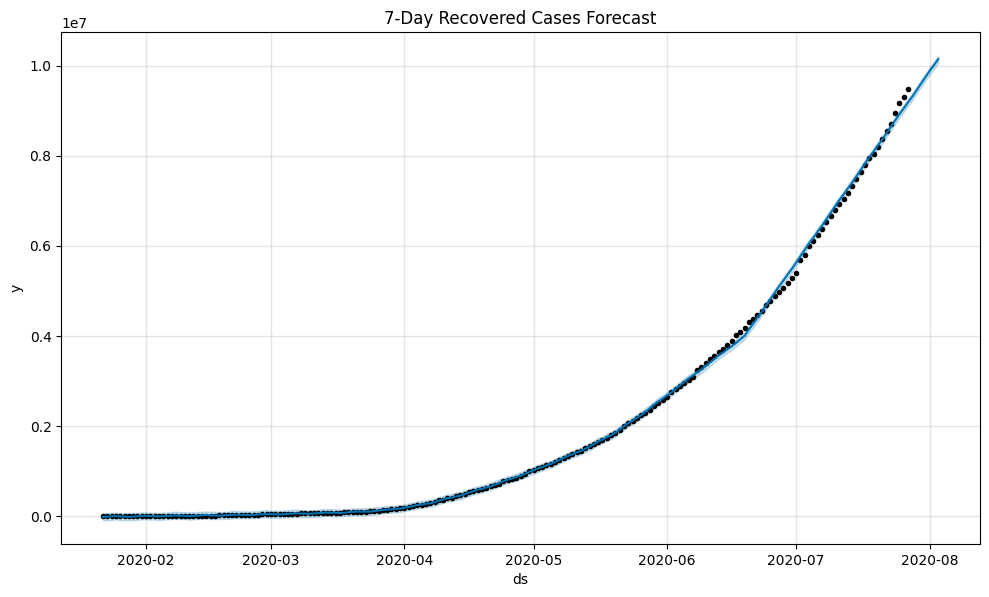

In [85]:
# 1. Forecast for Active Cases
active_cases = df.groupby(["Date"])["Active"].sum().reset_index()
prophet_active = active_cases.rename(columns={"Date": "ds", "Active": "y"})

model_active = Prophet()
model_active.fit(prophet_active)
future_active = model_active.make_future_dataframe(periods=7)
forecast_active = model_active.predict(future_active)

# Plot Active forecast
fig_active = model_active.plot(forecast_active)
plt.title("7-Day Active Cases Forecast")
plt.show()

# 2. Forecast for Recovered Cases
recovered_cases = df.groupby(["Date"])["Recovered"].sum().reset_index()
prophet_recovered = recovered_cases.rename(columns={"Date": "ds", "Recovered": "y"})

model_recovered = Prophet()
model_recovered.fit(prophet_recovered)
future_recovered = model_recovered.make_future_dataframe(periods=7)
forecast_recovered = model_recovered.predict(future_recovered)

# Plot Recovered forecast
fig_recovered = model_recovered.plot(forecast_recovered)
plt.title("7-Day Recovered Cases Forecast")
plt.show()

In [77]:
import plotly.express as px

In [78]:
world_data = df.groupby(["Country"])[['Confirmed', 'Deaths','Recovered', 'Active']].sum().reset_index()
world_data

,Country,Confirmed,Deaths,Recovered,Active
0,Afghanistan,1936390,49098,798240,1089052
1,Albania,196702,5708,118877,72117
2,Algeria,1179755,77972,755897,345886
3,Andorra,94404,5423,69074,19907
4,Angola,22662,1078,6573,15011
...,...,...,...,...,...
182,West Bank and Gaza,233461,1370,61124,170967
183,Western Sahara,901,63,648,190
184,Yemen,67180,17707,23779,25694
185,Zambia,129421,2643,83611,43167


In [89]:
figure = px.choropleth(world_data, locations="Country", locationmode="country names", color="Active", hover_name="Country", range_color=[1,100000], color_continuous_scale="reds", title="World Covid")
figure.show()